**Import libraries**

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(style="whitegrid", palette="deep")

**Load the dataset**

In [3]:
sales = pd.read_csv(
    SALES_FILE,
    parse_dates=[
        "transaction_date",
        "sales_month_start",
        "sales_week_start"
    ],
    low_memory=False
)

abc_xyz = pd.read_csv(
    ABC_XYZ_FILE,
    low_memory=False
)

print(f"Sales rows: {len(sales):,}")
print(f"Classified products: {len(abc_xyz):,}")

Sales rows: 125,751
Classified products: 2,326


In [4]:
#Use only positive sale quantities for demand forecasting
sale_lines = sales[
    (sales["transaction_type"] == "Sale")
    & (sales["quantity_sold"] > 0)
].copy()

**Select the products to forecast**


Begin with the top 20 Class A products by net sales

In [5]:
forecast_products = (
    abc_xyz[
        abc_xyz["abc_class"] == "A"
    ]
    .sort_values(
        "net_sales",
        ascending=False
    )
    .head(20)
    [
        [
            "product_no",
            "product_description",
            "abc_xyz_class",
            "net_sales"
        ]
    ]
)

display(forecast_products)

,product_no,product_description,abc_xyz_class,net_sales
345,PROD-140871,PROD-100439 SEG-500064 Scholar Footwear Boot C...,AZ,"104,027.50"
23,PROD-100805,PROD-102578 SEG-500351 Scholar Footwear Flight...,AY,"102,481.99"
24,PROD-100804,PROD-102576 SEG-500351 Scholar Footwear Flight...,AY,"72,822.50"
25,PROD-100803,PROD-102577 SEG-500351 Scholar Footwear Flight...,AY,"71,496.48"
346,PROD-140870,PROD-100438 SEG-500064 Scholar Footwear Boot C...,AZ,"61,705.00"
347,PROD-175338,PROD-113366 SEG-502458 Heritage Footwear Retro...,AZ,"60,040.00"
26,PROD-100802,PROD-102574 SEG-500351 Scholar Footwear Flight...,AY,"56,361.50"
348,PROD-140869,PROD-100437 SEG-500064 Scholar Footwear Boot C...,AZ,"55,251.90"
349,PROD-175334,PROD-113357 SEG-502458 Heritage Footwear Retro...,AZ,"51,110.00"
350,PROD-152143,PROD-162923 SEG-514991 Heritage Footwear Retro...,AZ,"45,672.00"


In [6]:
#Store the product numbers
selected_product_numbers = (
    forecast_products["product_no"]
    .astype(str)
    .tolist()
)

sale_lines["product_no"] = (
    sale_lines["product_no"].astype(str)
)

**Build complete monthly time series**


In [7]:
#Aggregate demand
monthly_demand = (
    sale_lines[
        sale_lines["product_no"].isin(
            selected_product_numbers
        )
    ]
    .groupby(
        [
            "product_no",
            "sales_month_start"
        ],
        as_index=False
    )
    .agg(
        monthly_units=(
            "quantity_sold",
            "sum"
        )
    )
)

In [8]:
#Create a complete product-month grid
all_months = pd.date_range(
    start=sales["sales_month_start"].min(),
    end=sales["sales_month_start"].max(),
    freq="MS"
)

complete_index = pd.MultiIndex.from_product(
    [
        selected_product_numbers,
        all_months
    ],
    names=[
        "product_no",
        "sales_month_start"
    ]
)

In [9]:
#Fill missing demand months with zero
complete_monthly_demand = (
    monthly_demand
    .set_index(
        [
            "product_no",
            "sales_month_start"
        ]
    )
    .reindex(
        complete_index,
        fill_value=0
    )
    .reset_index()
)

display(complete_monthly_demand.head())

,product_no,sales_month_start,monthly_units
0,PROD-140871,2025-06-01,7
1,PROD-140871,2025-07-01,28
2,PROD-140871,2025-08-01,100
3,PROD-140871,2025-09-01,59
4,PROD-140871,2025-10-01,88


In [ ]:
#Verify the number of observations per product
series_counts = (
    complete_monthly_demand
    .groupby("product_no")
    .size()
)

display(series_counts.head())

product_no
PROD-100439    11
PROD-100451    11
PROD-100799    11
PROD-100800    11
PROD-100801    11
dtype: int64

**Create the forecast-accuracy function**

We will calculate:
- MAE: average absolute forecasting error
- RMSE: penalizes larger forecasting errors
- WAPE: total absolute error as a percentage of demand
- Bias: whether the forecast generally over- or under-predicts

In [11]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    denominator = np.abs(actual).sum()

    wape = (
        np.abs(actual - predicted).sum()
        / denominator
        * 100
        if denominator != 0
        else np.nan
    )

    bias = (
        predicted - actual
    ).sum()

    bias_pct = (
        bias / denominator * 100
        if denominator != 0
        else np.nan
    )

    return {
        "mae": mae,
        "rmse": rmse,
        "wape_pct": wape,
        "forecast_bias": bias,
        "bias_pct": bias_pct
    }

**Create the forecasting functions**

In [12]:
#Naive Forecasting Function
def naive_forecast(train, periods):
    return np.repeat(
        train.iloc[-1],
        periods
    )

In [13]:
#Three month Moving Average Forecasting Function
def moving_average_forecast(
    train,
    periods,
    window=3
):
    window_size = min(
        window,
        len(train)
    )

    forecast_value = (
        train.tail(window_size).mean()
    )

    return np.repeat(
        forecast_value,
        periods
    )

In [14]:
#Simple Exponential Smoothing Forecasting Function
def exponential_smoothing_forecast(
    train,
    periods
):
    model = SimpleExpSmoothing(
        train,
        initialization_method="estimated"
    ).fit(
        optimized=True
    )

    return model.forecast(periods).values

**Evaluate the forecasting models**

Use the last three months as the test period

In [15]:
TEST_PERIODS = 3

In [16]:
#Create a function that evaluates one product
def evaluate_product_models(
    product_number,
    product_data,
    test_periods=3
):
    product_data = product_data.sort_values(
        "sales_month_start"
    )

    series = (
        product_data["monthly_units"]
        .astype(float)
        .reset_index(drop=True)
    )

    if len(series) <= test_periods:
        return pd.DataFrame()

    train = series.iloc[:-test_periods]
    test = series.iloc[-test_periods:]

    models = {
        "Naive": naive_forecast(
            train,
            test_periods
        ),
        "Moving Average": moving_average_forecast(
            train,
            test_periods,
            window=3
        ),
        "Exponential Smoothing":
            exponential_smoothing_forecast(
                train,
                test_periods
            )
    }

    results = []

    for model_name, predictions in models.items():
        predictions = np.maximum(
            predictions,
            0
        )

        metrics = calculate_metrics(
            test,
            predictions
        )

        results.append({
            "product_no": product_number,
            "model": model_name,
            **metrics
        })

    return pd.DataFrame(results)

In [17]:
evaluation_results = []

for product_number, product_data in (
    complete_monthly_demand.groupby(
        "product_no"
    )
):
    product_results = evaluate_product_models(
        product_number,
        product_data,
        test_periods=TEST_PERIODS
    )

    evaluation_results.append(
        product_results
    )

model_accuracy = pd.concat(
    evaluation_results,
    ignore_index=True
)

display(model_accuracy.head(15))

,product_no,model,mae,rmse,wape_pct,forecast_bias,bias_pct
0,PROD-100439,Naive,43.67,45.42,422.58,131.00,422.58
1,PROD-100439,Moving Average,31.67,34.04,306.45,95.00,306.45
2,PROD-100439,Exponential Smoothing,53.79,55.22,520.56,161.37,520.56
3,PROD-100451,Naive,16.67,16.67,64.94,-50.00,-64.94
4,PROD-100451,Moving Average,10.00,10.01,38.96,-30.00,-38.96
5,PROD-100451,Exponential Smoothing,16.67,16.67,64.94,-50.00,-64.94
6,PROD-100799,Naive,33.00,34.67,60.00,-99.00,-60.00
7,PROD-100799,Moving Average,18.67,21.47,33.94,-56.00,-33.94
8,PROD-100799,Exponential Smoothing,23.63,25.90,42.95,-70.88,-42.95
9,PROD-100800,Naive,42.00,44.32,66.67,-126.00,-66.67


**Select the best model**

Use the lowest WAPE as the main selection criterion

In [18]:
best_models = (
    model_accuracy
    .sort_values(
        [
            "product_no",
            "wape_pct",
            "mae"
        ]
    )
    .groupby(
        "product_no",
        as_index=False
    )
    .first()
)

In [19]:
#Rename the selected-model fields
best_models = best_models.rename(
    columns={
        "model": "best_model",
        "mae": "best_model_mae",
        "rmse": "best_model_rmse",
        "wape_pct": "best_model_wape_pct",
        "forecast_bias": "best_model_bias",
        "bias_pct": "best_model_bias_pct"
    }
)

display(best_models)


,product_no,best_model,best_model_mae,best_model_rmse,best_model_wape_pct,best_model_bias,best_model_bias_pct
0,PROD-100439,Moving Average,31.67,34.04,306.45,95.00,306.45
1,PROD-100451,Moving Average,10.00,10.01,38.96,-30.00,-38.96
2,PROD-100799,Moving Average,18.67,21.47,33.94,-56.00,-33.94
3,PROD-100800,Moving Average,29.00,32.27,46.03,-87.00,-46.03
4,PROD-100801,Moving Average,24.67,33.72,33.33,-74.00,-33.33
5,PROD-100802,Exponential Smoothing,28.87,42.48,35.21,-86.62,-35.21
6,PROD-100803,Moving Average,43.00,46.96,36.54,-129.00,-36.54
7,PROD-100804,Moving Average,53.67,57.02,43.28,-161.00,-43.28
8,PROD-100805,Moving Average,74.33,79.36,41.45,-223.00,-41.45
9,PROD-140867,Exponential Smoothing,3.16,3.68,30.57,0.43,1.38


In [20]:
#Summarize how often each model was selected
model_selection_summary = (
    best_models["best_model"]
    .value_counts()
    .rename_axis("best_model")
    .reset_index(name="products")
)

display(model_selection_summary)

,best_model,products
0,Moving Average,9
1,Naive,9
2,Exponential Smoothing,2


**Forecast the next three months**


Create a function that uses the selected model


In [21]:
def forecast_with_selected_model(
    series,
    model_name,
    periods=3
):
    series = (
        pd.Series(series)
        .astype(float)
        .reset_index(drop=True)
    )

    if model_name == "Naive":
        forecast = naive_forecast(
            series,
            periods
        )

    elif model_name == "Moving Average":
        forecast = moving_average_forecast(
            series,
            periods,
            window=3
        )

    elif model_name == "Exponential Smoothing":
        forecast = exponential_smoothing_forecast(
            series,
            periods
        )

    else:
        raise ValueError(
            f"Unknown model: {model_name}"
        )

    return np.maximum(
        np.asarray(forecast),
        0
    )

In [22]:
#Generate future dates
last_observed_month = (
    complete_monthly_demand[
        "sales_month_start"
    ].max()
)

future_months = pd.date_range(
    start=last_observed_month
    + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

print(future_months)

DatetimeIndex(['2026-05-01', '2026-06-01', '2026-07-01'], dtype='datetime64[us]', freq='MS')


In [ ]:
#Generate future forecasts for each product
future_forecasts = []

for product_number, product_data in (
    complete_monthly_demand.groupby(
        "product_no"
    )
):
    selected_model = (
        best_models.loc[
            best_models["product_no"]
            == product_number,
            "best_model"
        ].iloc[0]
    )

    product_series = (
        product_data
        .sort_values("sales_month_start")
        ["monthly_units"]
    )

    predictions = forecast_with_selected_model(
        product_series,
        selected_model,
        periods=3
    )

    for forecast_month, forecast_units in zip(
        future_months,
        predictions
    ):
        future_forecasts.append({
            "product_no": product_number,
            "forecast_month": forecast_month,
            "forecast_units": round(
                float(forecast_units),
                2
            ),
            "selected_model": selected_model
        })

future_forecasts = pd.DataFrame(
    future_forecasts
)

display(future_forecasts.head(15))

,product_no,forecast_month,forecast_units,selected_model
0,PROD-100439,2026-05-01,10.33,Moving Average
1,PROD-100439,2026-06-01,10.33,Moving Average
2,PROD-100439,2026-07-01,10.33,Moving Average
3,PROD-100451,2026-05-01,25.67,Moving Average
4,PROD-100451,2026-06-01,25.67,Moving Average
5,PROD-100451,2026-07-01,25.67,Moving Average
6,PROD-100799,2026-05-01,55.00,Moving Average
7,PROD-100799,2026-06-01,55.00,Moving Average
8,PROD-100799,2026-07-01,55.00,Moving Average
9,PROD-100800,2026-05-01,63.00,Moving Average


**Add product information and accuracy**

In [24]:
future_forecasts = (
    future_forecasts
    .merge(
        forecast_products,
        on="product_no",
        how="left"
    )
    .merge(
        best_models,
        on="product_no",
        how="left"
    )
)

display(future_forecasts.head())

,product_no,forecast_month,forecast_units,selected_model,product_description,abc_xyz_class,net_sales,best_model,best_model_mae,best_model_rmse,best_model_wape_pct,best_model_bias,best_model_bias_pct
0,PROD-100439,2026-05-01,10.33,Moving Average,PROD-164668 SEG-515333 Scholar Footwear Court ...,AY,"36,847.11",Moving Average,31.67,34.04,306.45,95.00,306.45
1,PROD-100439,2026-06-01,10.33,Moving Average,PROD-164668 SEG-515333 Scholar Footwear Court ...,AY,"36,847.11",Moving Average,31.67,34.04,306.45,95.00,306.45
2,PROD-100439,2026-07-01,10.33,Moving Average,PROD-164668 SEG-515333 Scholar Footwear Court ...,AY,"36,847.11",Moving Average,31.67,34.04,306.45,95.00,306.45
3,PROD-100451,2026-05-01,25.67,Moving Average,PROD-100827 SEG-500112 Heritage Footwear Fligh...,AX,"36,920.50",Moving Average,10.00,10.01,38.96,-30.00,-38.96
4,PROD-100451,2026-06-01,25.67,Moving Average,PROD-100827 SEG-500112 Heritage Footwear Fligh...,AX,"36,920.50",Moving Average,10.00,10.01,38.96,-30.00,-38.96


**Export forecasting results**

In [25]:
model_accuracy.to_csv(
    DATA_DIR / "forecast_model_accuracy.csv",
    index=False
)

best_models.to_csv(
    DATA_DIR / "best_forecast_models.csv",
    index=False
)

future_forecasts.to_csv(
    DATA_DIR / "product_demand_forecast.csv",
    index=False
)

print("Forecast files saved successfully.")

Forecast files saved successfully.


**Plot one product’s forecast**


Select the highest-value forecast product:

In [26]:
example_product = (
    forecast_products.iloc[0]["product_no"]
)

example_history = (
    complete_monthly_demand[
        complete_monthly_demand["product_no"]
        == example_product
    ]
    .sort_values("sales_month_start")
)

example_forecast = (
    future_forecasts[
        future_forecasts["product_no"]
        == example_product
    ]
    .sort_values("forecast_month")
)

example_description = (
    forecast_products.iloc[0][
        "product_description"
    ]
)

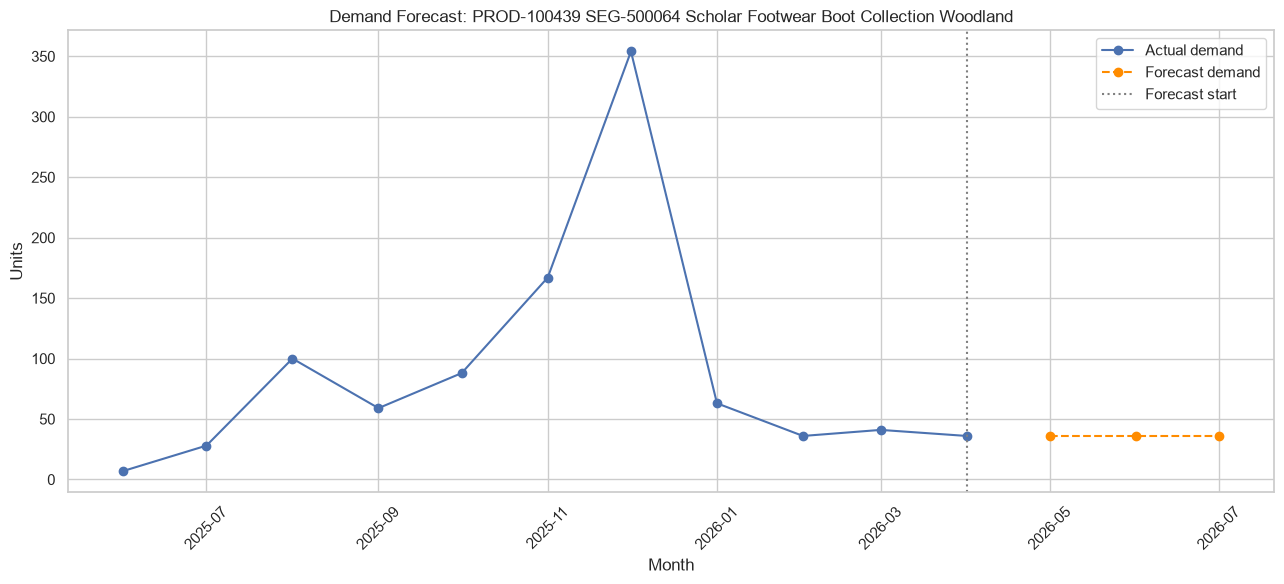

In [27]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    example_history["sales_month_start"],
    example_history["monthly_units"],
    marker="o",
    label="Actual demand"
)

ax.plot(
    example_forecast["forecast_month"],
    example_forecast["forecast_units"],
    marker="o",
    linestyle="--",
    color="darkorange",
    label="Forecast demand"
)

ax.axvline(
    last_observed_month,
    color="grey",
    linestyle=":",
    label="Forecast start"
)

ax.set_title(
    f"Demand Forecast: {example_description}"
)

ax.set_xlabel("Month")
ax.set_ylabel("Units")
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "example_product_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

These forecasts are portfolio demonstrations based only on historical demand. They do not include promotions, lead times, supplier constraints, holidays or pricing changes, so document them as analytical estimates rather than production forecasts.